In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy import special

# Part b

In [ ]:
n_lambs = 2 * (10 ** 4)
n_steps = 10 ** 4

R = np.zeros((n_steps, n_lambs))
W = np.full((n_steps, n_lambs), 10)

for T in range(1, n_steps):
    lamb_change = np.array([1 if i == 1 else -1 for i in np.random.binomial(1, 0.5, n_lambs)])
    lion_change = np.array([1 if i == 1 else -1 for i in np.random.binomial(1, 0.5, n_lambs)])
    R[T] = R[T - 1] + lamb_change
    W[T] = W[T - 1] + lion_change

D = np.abs(R - W)
first_zero = np.where(np.any(D == 0, axis=0), np.argmax(D == 0, axis=0), np.inf)

S = []
for t in range(10**4):
    St = sum(first_zero > t) / len(first_zero)
    S.append(St)

res = stats.linregress(np.log(range(10**2, 10**4)), np.log(S[10**2:10**4]))

d_0 = 10

S_prime = []
for t in range(1,10**4):
    S_primet = special.erf(d_0 / (2 * (t ** 0.5)))
    S_prime.append(S_primet)

plt.scatter(range(10**4), S)
plt.scatter(range(1,10**4), S_prime, s = 1)
plt.title(f"Problem 4b: Slope {res.slope:.{3}f}")
plt.xscale('log')
plt.yscale('log')
plt.savefig("hw3_p4b.png")

np.float64(-0.4836681439357778)

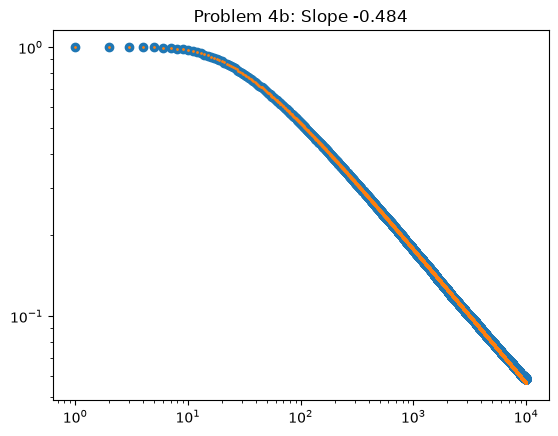

# Part c

t = 10^2: 0.3395 0.27092012280339633
t = 10^3: 0.0638 0.03130660509319347
t = 10^4: 0.01085 0.0031781171631304677
Covariance of increments: 1
Correlation of increments: 0.5


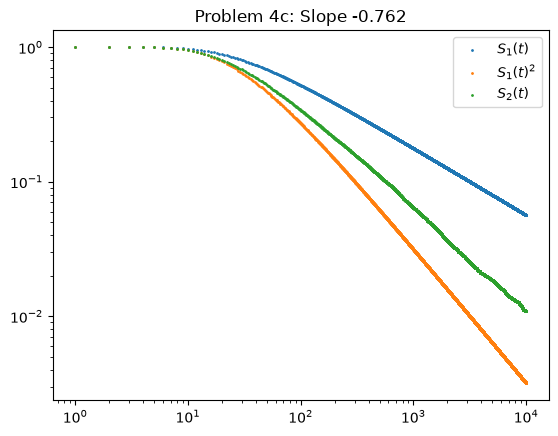

In [ ]:
# Part (c)

W1 = np.full((n_steps, n_lambs), 10)
W2 = np.full((n_steps, n_lambs), 10)

for T in range(1, n_steps):
    lamb_change = np.array([1 if i == 1 else -1 for i in np.random.binomial(1, 0.5, n_lambs)])
    lion1_change = np.array([1 if i == 1 else -1 for i in np.random.binomial(1, 0.5, n_lambs)])
    lion2_change = np.array([1 if i == 1 else -1 for i in np.random.binomial(1, 0.5, n_lambs)])

    R[T] = R[T - 1] + lamb_change
    W1[T] = W1[T - 1] + lion1_change
    W2[T] = W2[T - 1] + lion2_change

D1 = np.abs(R - W1)
D2 = np.abs(R - W2)

first_zero1 = np.where(np.any(D1 == 0, axis=0), np.argmax(D1 == 0, axis=0), np.inf)
first_zero2 = np.where(np.any(D2 == 0, axis=0), np.argmax(D2 == 0, axis=0), np.inf)

first_zero_two = np.minimum(first_zero1, first_zero2)

S2 = []
for t in range(10**4):
    S2t = sum(first_zero_two > t) / len(first_zero_two)
    S2.append(S2t)

res2 = stats.linregress(
    np.log(range(10**2, 10**4)),
    np.log(S2[10**2:10**4])
)

plt.scatter(range(10**4), S2, s = 1)
plt.scatter(range(10**4), np.array(S) ** 2, s = 1)

plt.title(f"Problem 4c: Slope {res2.slope:.3f}")
plt.xscale('log')
plt.yscale('log')

print("t = 10^2:", S2[10**2], S[10**2] ** 2)
print("t = 10^3:", S2[10**3], S[10**3] ** 2)
print("t = 10^4:", S2[10**4 - 1], S[10**4 - 1] ** 2)